# OXFORD-IIIT PET Dataset EDA

xmls/		Head bounding box annotations in PASCAL VOC Format

list.txt	Combined list of all images in the dataset
		Each entry in the file is of following nature:
		Image CLASS-ID SPECIES BREED ID
		ID: 1:37 Class ids
		SPECIES: 1:Cat 2:Dog
		BREED ID: 1-25:Cat 1:12:Dog
		All images with 1st letter as captial are cat images while
		images with small first letter are dog images.
trainval.txt	Files describing splits used in the paper.However,
test.txt	you are encouraged to try random splits.

**용어 정리** (이 노트북은 README 표현을 그대로 쓴다)
- **CLASS-ID**: 1~37. 37개 품종을 구분하는 ID다. 이 노트북에서 "37개 클래스"는 항상 CLASS-ID를 뜻한다. 파일명의 품종명(예: `american_bulldog`)과 1:1로 대응한다.
- **SPECIES**: 1=Cat, 2=Dog.
- **BREED ID**: SPECIES 안에서 매긴 품종 번호다 (Cat 1~12, Dog 1~25). Cat과 Dog의 번호가 겹치므로(예: Cat 1번과 Dog 1번이 따로 있음) **BREED ID만으로는 37개 품종을 구분할 수 없다.**

## EDA 계획

### 1. 파일·split 정합성 점검
- **항목**: trainval/test의 이미지 수와 비율, 목록과 실제 파일의 양방향 일치 여부, 이름·해시 기준 중복(분할 내/분할 간)을 확인한다.
- **목적**: 누락·중복·누수 없이 신뢰할 수 있는 이미지 집합을 확정한다.

### 2. split별 XML(박스 정답) 보유 여부 점검
- **항목**: 각 split에서 대응하는 XML이 존재하는 이미지 수를 세고, 어느 split 목록에도 없는 XML을 찾는다.
- **목적**: 학습·평가에 실제로 쓸 수 있는 데이터 범위를 파악하고, 재분할 필요 여부를 판단한다.

### 3. 라벨 정합성 점검
- **항목**: 파일명 첫 글자(대/소문자)와 SPECIES, 파일명의 품종명과 CLASS-ID / BREED ID가 일치하는지 확인한다.
- **목적**: 메타데이터 규칙이 실제로 지켜지는지 검증해 라벨 오류를 걸러낸다.

### 4. CLASS-ID·SPECIES 분포 점검
- **항목**: CLASS-ID(37개)별, SPECIES(Cat/Dog)별 이미지 수를 전체 기준과 XML 보유 이미지 기준으로 각각 집계한다.
- **목적**: README의 "roughly 200 images for each class" 주장을 검증하고, 학습 데이터에서 CLASS-ID 간 불균형이 있는지 확인한다.

### 5. XML·바운딩 박스 품질 점검
- **항목**: XML 내 `<size>`와 실제 이미지 크기 일치, 박스 좌표 유효성(경계 이탈, `xmin >= xmax` 등), XML당 object 개수, `difficult`/`truncated` 분포를 확인한다.
- **목적**: 잘못된 박스를 사전에 찾아내고, Dataset 코드에서 처리해야 할 예외를 정리한다.

### 6. 박스 위치 시각적 검증
- **항목**: CLASS-ID별로 무작위 샘플 몇 장에 헤드 박스를 그려 실제 머리를 가리키는지 육안으로 확인한다.
- **목적**: 수치 검사로 잡히지 않는 어노테이션 오류가 있는지 표본으로 확인한다.

### 7. 이미지 모드·크기 점검
- **항목**: 이미지 모드(RGB/L/RGBA/P) 분포, 이미지 크기와 종횡비 분포를 split·SPECIES별로 확인한다.
- **목적**: 로딩 시 RGB 변환과 리사이즈 정책 등 전처리 방식을 결정한다.

### 8. 바운딩 박스 통계 분석
- **항목**: 이미지 대비 박스 면적 비율, 박스 종횡비, 박스 중심 위치 분포를 확인한다.
- **목적**: SSD default box(anchor)의 scale·aspect ratio 설정과 크롭 증강 범위의 근거를 마련한다.

### 9. 데이터 증강 미리보기
- **항목**: SPECIES(Cat/Dog)와 박스 크기가 다른 대표 이미지 몇 장을 골라 좌우 반전, 미세 회전(±10° 내외), 얼굴을 포함하는 랜덤 크롭·확대, 밝기·대비 조절, 노이즈를 적용하고 변환된 박스를 함께 그려 확인한다.
- **목적**: 증강 후에도 박스가 얼굴을 정확히 감싸는지 검증해 학습에 쓸 증강 조합을 정한다.

### 10. EDA 결론 정리
- **항목**: 위 분석 결과를 바탕으로 데이터 분할 전략, 제외할 데이터, 전처리·증강·anchor 설정을 정리한다.
- **목적**: EDA에서 얻은 근거를 모델링 단계의 구체적인 결정 사항으로 연결한다.


## 0. 환경 설정 및 데이터 로드

분석에 필요한 라이브러리와 경로를 설정하고, `list.txt` / `trainval.txt` / `test.txt`를 DataFrame으로 불러온다.
- 데이터는 `./data` 아래에 Kaggle 압축을 푼 구조(`images/images`, `annotations/annotations`)를 가정한다. Colab 등 다른 환경에서는 `DATA_DIR`만 바꾸면 된다.
- 이후 모든 무작위 샘플링은 재현성을 위해 `SEED`를 고정한다.

In [25]:
import hashlib
import random
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = Path("./data")
IMG_DIR = DATA_DIR / "images" / "images"
ANN_DIR = DATA_DIR / "annotations" / "annotations"
XML_DIR = ANN_DIR / "xmls"

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 160)


def read_split(path):
    """Image CLASS-ID SPECIES BREED-ID 형식의 split 파일을 읽는다 ('#' 주석 줄은 무시)."""
    return pd.read_csv(path, sep=r"\s+", header=None, comment="#",
                       names=["image", "class_id", "species", "breed_id"])


def breed_of(name):
    """파일명(확장자 제외)에서 품종명을 추출한다. 예: 'american_bulldog_12' -> 'american_bulldog'"""
    return name.rsplit("_", 1)[0]


list_df = read_split(ANN_DIR / "list.txt")
trainval_df = read_split(ANN_DIR / "trainval.txt").assign(split="trainval")
test_df = read_split(ANN_DIR / "test.txt").assign(split="test")
split_df = pd.concat([trainval_df, test_df], ignore_index=True)

print(f"list.txt     : {len(list_df):,}행")
print(f"trainval.txt : {len(trainval_df):,}행")
print(f"test.txt     : {len(test_df):,}행")
split_df.head()

list.txt     : 7,349행
trainval.txt : 3,680행
test.txt     : 3,669행


,image,class_id,species,breed_id,split
0,Abyssinian_100,1,1,1,trainval
1,Abyssinian_101,1,1,1,trainval
2,Abyssinian_102,1,1,1,trainval
3,Abyssinian_103,1,1,1,trainval
4,Abyssinian_104,1,1,1,trainval


## 1. 파일·split 정합성 점검

### 1-1. split별 이미지 수와 비율
trainval/test가 어떤 비율로 나뉘어 있는지, `list.txt`가 두 split의 합집합과 같은지 확인한다.

In [26]:
summary = split_df["split"].value_counts().to_frame("count")
summary["ratio"] = (summary["count"] / summary["count"].sum()).round(3)
display(summary)

same = set(list_df["image"]) == set(split_df["image"])
print(f"list.txt == trainval ∪ test : {same}")

,count,ratio
split,,
trainval,3680,0.501
test,3669,0.499


list.txt == trainval ∪ test : True


### 1-2. 목록 ↔ 실제 파일 양방향 일치 여부
- 목록에 있는데 파일이 없는 경우 → 학습 중 로딩 에러가 난다.
- 파일은 있는데 목록에 없는 경우 → 공식 split에서 빠진 이미지로, 데이터가 숨어 있을 수 있다.
- 이미지 폴더에 `.jpg`가 아닌 파일이 섞여 있는지도 함께 확인한다.

In [27]:
all_files = sorted(p for p in IMG_DIR.iterdir() if p.is_file())
print("이미지 폴더 확장자 분포:", Counter(p.suffix.lower() for p in all_files))
print("jpg가 아닌 파일:", [p.name for p in all_files if p.suffix.lower() != ".jpg"])

jpg_paths = [p for p in all_files if p.suffix.lower() == ".jpg"]
img_names = {p.stem for p in jpg_paths}
listed = set(split_df["image"])

missing_files = sorted(listed - img_names)
unlisted_imgs = sorted(img_names - listed)
print(f"\n목록에 있지만 파일이 없는 이미지 : {len(missing_files)}개 {missing_files[:10]}")
print(f"파일은 있지만 목록에 없는 이미지 : {len(unlisted_imgs)}개")
pd.Series([breed_of(n) for n in unlisted_imgs]).value_counts().to_frame("unlisted_count").T

이미지 폴더 확장자 분포: Counter({'.jpg': 7390, '.mat': 3})
jpg가 아닌 파일: ['Abyssinian_100.mat', 'Abyssinian_101.mat', 'Abyssinian_102.mat']

목록에 있지만 파일이 없는 이미지 : 0개 []
파일은 있지만 목록에 없는 이미지 : 41개


,Bombay,Egyptian_Mau,english_cocker_spaniel,newfoundland,Abyssinian,staffordshire_bull_terrier,Siamese,boxer,keeshond
unlisted_count,16,10,4,4,2,2,1,1,1


### 1-3. 이미지 이름 중복
같은 이름이 split 내부에 두 번 이상 있거나, trainval과 test에 동시에 있는지 확인한다.

In [28]:
for name, df in [("list", list_df), ("trainval", trainval_df), ("test", test_df)]:
    print(f"{name:9s} 내부 이름 중복: {df['image'].duplicated().sum()}개")
print(f"trainval ∩ test 이름 중복 : {len(set(trainval_df['image']) & set(test_df['image']))}개")

list      내부 이름 중복: 0개
trainval  내부 이름 중복: 0개
test      내부 이름 중복: 0개
trainval ∩ test 이름 중복 : 0개


### 1-4. 해시(MD5) 기준 완전 중복 이미지
이름은 달라도 바이트가 완전히 같은 이미지가 있으면 split 간 데이터 누수가 생긴다. 모든 jpg의 MD5를 계산해 같은 해시를 가진 그룹을 찾고, 그 그룹이 split 내부 중복인지 split 간 중복인지 구분한다.

In [29]:
def md5_of(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


split_of = split_df.set_index("image")["split"]
hash_df = pd.DataFrame({
    "image": [p.stem for p in jpg_paths],
    "md5": [md5_of(p) for p in tqdm(jpg_paths, desc="hashing")],
})
hash_df["split"] = hash_df["image"].map(split_of).fillna("unlisted")

dup_df = hash_df[hash_df.duplicated("md5", keep=False)].sort_values(["md5", "image"])
dup_groups = dup_df.groupby("md5")["split"].agg(lambda s: " + ".join(sorted(s)))
print(f"중복 해시 그룹 수: {dup_df['md5'].nunique()}개 (관련 이미지 {len(dup_df)}장)")
display(dup_groups.value_counts().to_frame("groups"))
dup_df

hashing: 100%|██████████| 7390/7390 [00:02<00:00, 2788.32it/s]

중복 해시 그룹 수: 29개 (관련 이미지 59장)


,groups
split,
trainval + unlisted,22
test + unlisted,6
trainval + unlisted + unlisted,1


,image,md5,split
699,Bombay_198,0a1987c63342e5a34544695d703301e5,trainval
766,Bombay_69,0a1987c63342e5a34544695d703301e5,unlisted
611,Bombay_109,100a66eea3e58933382efa23d84b4146,trainval
708,Bombay_206,100a66eea3e58933382efa23d84b4146,unlisted
602,Bombay_100,1b75f5ddeaec6ed36dad913ec3b76eb8,trainval
612,Bombay_11,1b75f5ddeaec6ed36dad913ec3b76eb8,unlisted
696,Bombay_192,1b75f5ddeaec6ed36dad913ec3b76eb8,unlisted
702,Bombay_200,1c980db2d6c91990204ba23808983c1d,test
784,Bombay_85,1c980db2d6c91990204ba23808983c1d,unlisted
1112,Egyptian_Mau_210,20e6d94b3be86da62f465b325e3a3f08,test


### 💡 1장 인사이트 & 결정사항

**인사이트**
- `trainval` 3,680장, `test` 3,669장으로 공식 split은 약 **50:50**이다. `list.txt`는 두 split의 합집합과 정확히 같다.
- 목록에 있는데 파일이 없는 이미지는 **0장**이다. 반대로 파일은 있는데 어느 목록에도 없는 이미지가 **41장** 있다. Bombay(16), Egyptian_Mau(10)에 몰려 있다.
- 이미지 폴더에 `.mat` 파일 3개(`Abyssinian_100~102.mat`)가 섞여 있다.
- 이름 중복은 split 안에서도, split 사이에서도 없다.
- MD5 기준으로 바이트가 똑같은 이미지 그룹이 **29개(59장)** 있다. **모든 그룹이 "목록에 있는 이미지 1장 + 목록에 없는 복사본"** 구조다. 목록에 없는 41장 대부분은 공식 split 이미지를 다른 이름으로 복사한 것이다.
- 공식 split끼리(trainval ↔ test)나 같은 split 안에서는 해시 중복이 없다. 따라서 **공식 목록만 쓰면 누수가 없다.**

**결정사항**
- 이미지 목록은 폴더 glob이 아니라 **split 파일 기준**으로 만든다. 그러면 `.mat`과 복사본이 자연스럽게 빠진다.
- list.txt에 있는 이미지만 사용하고, list.txt에 없는 이미지는 기본적으로 쓰지 않는다.

## 2. split별 XML(박스 정답) 보유 여부 점검

Detection 학습·평가에는 박스 정답(XML)이 반드시 필요하다. split별로 XML이 있는 이미지 수를 세고, 목록에 없는 XML·이미지 파일이 없는 XML도 찾는다.

In [30]:
xml_paths = sorted(p for p in XML_DIR.glob("*.xml") if not p.name.startswith("._"))
xml_names = {p.stem for p in xml_paths}
print(f"XML 파일 수: {len(xml_paths):,}개")

split_df["has_xml"] = split_df["image"].isin(xml_names)
display(pd.crosstab(split_df["split"], split_df["has_xml"], margins=True))

xml_unlisted = sorted(xml_names - listed)
xml_no_image = sorted(xml_names - img_names)
print(f"split 목록에 없는 XML : {len(xml_unlisted)}개 {xml_unlisted}")
print(f"이미지 파일이 없는 XML: {len(xml_no_image)}개 {xml_no_image}")
no_xml_trainval = split_df[(split_df["split"] == "trainval") & ~split_df["has_xml"]]["image"].tolist()
print(f"XML이 없는 trainval 이미지: {len(no_xml_trainval)}개 {no_xml_trainval}")

XML 파일 수: 3,686개


has_xml,False,True,All
split,,,
test,3669,0,3669
trainval,9,3671,3680
All,3678,3671,7349


split 목록에 없는 XML : 15개 ['Bombay_11', 'Bombay_189', 'Bombay_190', 'Bombay_192', 'Egyptian_Mau_129', 'Egyptian_Mau_183', 'Siamese_203', 'english_cocker_spaniel_162', 'english_cocker_spaniel_163', 'english_cocker_spaniel_164', 'english_cocker_spaniel_179', 'newfoundland_152', 'newfoundland_153', 'newfoundland_154', 'newfoundland_155']
이미지 파일이 없는 XML: 0개 []
XML이 없는 trainval 이미지: 9개 ['Abyssinian_104', 'Bengal_111', 'samoyed_10', 'Bengal_175', 'Egyptian_Mau_14', 'Egyptian_Mau_156', 'Egyptian_Mau_186', 'Ragdoll_199', 'saint_bernard_15']


### 2-1. 목록에 없는 XML은 쓸 수 있는가?
split 목록에 없는 XML 15개가 1-4에서 찾은 중복 이미지와 겹치는지 확인한다. trainval 이미지의 복사본이라면, 추가로 넣어도 새 정보가 없고 분할 시 누수만 생긴다.

In [31]:
md5_of_name = hash_df.set_index("image")["md5"]
listed_md5 = hash_df[hash_df["split"] != "unlisted"].groupby("md5")["image"].apply(list)
unlisted_xml_df = pd.DataFrame({"image": xml_unlisted})
unlisted_xml_df["duplicate_of_listed"] = unlisted_xml_df["image"].map(md5_of_name).map(listed_md5)
unlisted_xml_df["is_duplicate"] = unlisted_xml_df["duplicate_of_listed"].notna()
print("중복 여부:", unlisted_xml_df["is_duplicate"].value_counts().to_dict())
unlisted_xml_df

중복 여부: {True: 13, False: 2}


,image,duplicate_of_listed,is_duplicate
0,Bombay_11,[Bombay_100],True
1,Bombay_189,[Bombay_164],True
2,Bombay_190,[Bombay_185],True
3,Bombay_192,[Bombay_100],True
4,Egyptian_Mau_129,NaN,False
5,Egyptian_Mau_183,[Egyptian_Mau_10],True
6,Siamese_203,NaN,False
7,english_cocker_spaniel_162,[english_cocker_spaniel_151],True
8,english_cocker_spaniel_163,[english_cocker_spaniel_152],True
9,english_cocker_spaniel_164,[english_cocker_spaniel_154],True


### 💡 2장 인사이트 & 결정사항

**인사이트**
- **`test.txt`의 3,669장에는 XML(박스 정답)이 하나도 없다.** 공식 test split으로는 mAP·IoU 같은 Detection 정량 평가를 할 수 없다.
- `trainval` 3,680장 중 **3,671장**에 XML이 있다. XML이 없는 이미지는 9장이다. 
- list.txt에 없는 XML 15개 중 **13개는 trainval 이미지의 해시 복사본**이다. 따라서 무시해도 된다. 분할할 때 원본과 복사본이 train/test로 갈라지면 누수가 생긴다. 따라서 데이터셋 구성에서는 반드시 list.txt에 있는 이미지만 사용한다. 
- 복사본이 아닌 나머지 2개(`Egyptian_Mau_129`, `Siamese_203`)는 list.txt에는 없지만 이미지와 XML은 있는 쌍이다.

**결정사항**
- trainval.txt 중 XML이 없는 9장은 제외하고, list.txt에 없지만 XML과 이미지가 있는 쌍은 데이터로 활용한다. 
- **Detection 데이터 = trainval.txt 중 XML이 있는 3,671장 + 복사본이 아닌 list.txt에 없는 XML 2장(`Egyptian_Mau_129`, `Siamese_203`) = 3,673장.** 복사본 XML 13개는 제외한다.
- 이 3,673장을 **CLASS-ID(37개) 기준 stratified split**으로 train/val/test = **70/15/15**로 다시 나눈다. README에도 "random split을 권장한다"고 적혀 있다. 시드는 고정한다.
- 공식 `test.txt` 이미지는 정답이 없으므로 **예측 결과를 눈으로 확인하는 정성 평가에만** 쓴다.

## 3. 라벨 정합성 점검

README의 규칙이 실제로 지켜지는지 확인한다.
- 파일명 첫 글자가 대문자면 Cat(SPECIES=1), 소문자면 Dog(SPECIES=2)
- 같은 품종명은 항상 같은 CLASS-ID / BREED ID를 가진다 (1:1 대응)
- BREED ID 범위: Cat 1~12, Dog 1~25 (README 원문은 "1-25:Cat 1:12:Dog"로 적혀 있어 실제 값으로 검증한다)

In [32]:
split_df["breed"] = split_df["image"].map(breed_of)
split_df["species_by_case"] = np.where(split_df["image"].str[0].str.isupper(), 1, 2)

case_mismatch = split_df[split_df["species"] != split_df["species_by_case"]]
print(f"대소문자 규칙과 SPECIES가 다른 행: {len(case_mismatch)}개")

print("품종명 → CLASS-ID 종류 수 최대:", split_df.groupby("breed")["class_id"].nunique().max())
print("CLASS-ID → 품종명 종류 수 최대:", split_df.groupby("class_id")["breed"].nunique().max())
print("품종명 → BREED-ID 종류 수 최대:", split_df.groupby("breed")["breed_id"].nunique().max())

display(split_df.groupby("species")["breed_id"].agg(["min", "max", "nunique"])
        .rename(index={1: "cat", 2: "dog"}))

# 목록에 없는 이미지까지 포함해, 같은 품종명이 대소문자를 섞어 쓰는 경우가 있는지 확인
breeds_all = {breed_of(n) for n in img_names}
lower_groups = Counter(b.lower() for b in breeds_all)
print("대소문자만 다른 품종명:", [b for b, c in lower_groups.items() if c > 1])
print("전체 이미지 기준 품종 수:", len(breeds_all))

class_map = (split_df.groupby("class_id")
             .agg(breed=("breed", "first"), species=("species", "first"))
             .assign(species=lambda d: d["species"].map({1: "cat", 2: "dog"})))
class_map.T

대소문자 규칙과 SPECIES가 다른 행: 0개
품종명 → CLASS-ID 종류 수 최대: 1
CLASS-ID → 품종명 종류 수 최대: 1
품종명 → BREED-ID 종류 수 최대: 1


,min,max,nunique
species,,,
cat,1,12,12
dog,1,25,25


대소문자만 다른 품종명: []
전체 이미지 기준 품종 수: 37


class_id,1,2,3,4,5,6,7,8,9,10,...,28,29,30,31,32,33,34,35,36,37
breed,Abyssinian,american_bulldog,american_pit_bull_terrier,basset_hound,beagle,Bengal,Birman,Bombay,boxer,British_Shorthair,...,Russian_Blue,saint_bernard,samoyed,scottish_terrier,shiba_inu,Siamese,Sphynx,staffordshire_bull_terrier,wheaten_terrier,yorkshire_terrier
species,cat,dog,dog,dog,dog,cat,cat,cat,dog,cat,...,cat,dog,dog,dog,dog,cat,cat,dog,dog,dog


### 💡 3장 인사이트 & 결정사항

**인사이트**
- "대문자로 시작하면 Cat, 소문자로 시작하면 Dog" 규칙은 **예외 없이 지켜진다** (불일치 0건).
- 품종명 ↔ CLASS-ID ↔ (SPECIES, BREED ID) 쌍은 모두 **1:1 대응**이고, 대소문자만 다른 품종명도 없다.
- BREED ID 범위는 실제로 **Cat 1~12, Dog 1~25**다. README의 "1-25:Cat 1:12:Dog"는 표기 오류다. SPECIES별 품종 수(= CLASS-ID 수)는 Cat 12개, Dog 25개다.

**결정사항**
- 라벨은 trainval.txt 파일의 CLASS-ID(`class_id`) / SPECIES(`species`)를 그대로 쓴다. 목록 외 XML 2장처럼 split 파일에 없는 이미지는 파일명 규칙으로 라벨을 붙여도 안전하다.

## 4. CLASS-ID·SPECIES 분포 점검

README의 "37 category, roughly 200 images for each class"를 검증하고, 실제로 학습에 쓸 **XML이 있는 이미지** 기준으로 CLASS-ID 간 불균형이 생기는지 확인한다.

In [33]:
all_img_df = pd.DataFrame({"image": sorted(img_names)})
all_img_df["breed"] = all_img_df["image"].map(breed_of)
all_img_df["species"] = np.where(all_img_df["image"].str[0].str.isupper(), "cat", "dog")
all_img_df["split"] = all_img_df["image"].map(split_of).fillna("unlisted")
all_img_df["has_xml"] = all_img_df["image"].isin(xml_names)

breed_order = class_map["breed"].tolist()
counts = pd.DataFrame({
    "all_images": all_img_df["breed"].value_counts(),
    "trainval": all_img_df.query("split == 'trainval'")["breed"].value_counts(),
    "test": all_img_df.query("split == 'test'")["breed"].value_counts(),
    "unlisted": all_img_df.query("split == 'unlisted'")["breed"].value_counts(),
    "with_xml": all_img_df.query("has_xml")["breed"].value_counts(),
}).reindex(breed_order).fillna(0).astype(int)
counts["xml_ratio"] = (counts["with_xml"] / counts["all_images"]).round(2)

display(counts.describe().round(1))
display(pd.crosstab(all_img_df["species"], all_img_df["has_xml"], margins=True))
counts.sort_values("with_xml")

,all_images,trainval,test,unlisted,with_xml,xml_ratio
count,37.0,37.0,37.0,37.0,37.0,37.0
mean,199.7,99.5,99.2,1.1,99.6,0.5
std,1.5,1.6,2.7,3.1,1.4,0.0
min,191.0,93.0,88.0,0.0,92.0,0.5
25%,200.0,100.0,100.0,0.0,100.0,0.5
50%,200.0,100.0,100.0,0.0,100.0,0.5
75%,200.0,100.0,100.0,0.0,100.0,0.5
max,200.0,100.0,100.0,16.0,100.0,0.5


has_xml,False,True,All
species,,,
cat,1212,1188,2400
dog,2492,2498,4990
All,3704,3686,7390


,all_images,trainval,test,unlisted,with_xml,xml_ratio
breed,,,,,,
Egyptian_Mau,200,93,97,10,92,0.46
Bengal,200,100,100,0,98,0.49
Abyssinian,200,100,98,2,99,0.50
samoyed,200,100,100,0,99,0.50
saint_bernard,200,100,100,0,99,0.50
Ragdoll,200,100,100,0,99,0.50
miniature_pinscher,200,100,100,0,100,0.50
newfoundland,200,96,100,4,100,0.50
Persian,200,100,100,0,100,0.50


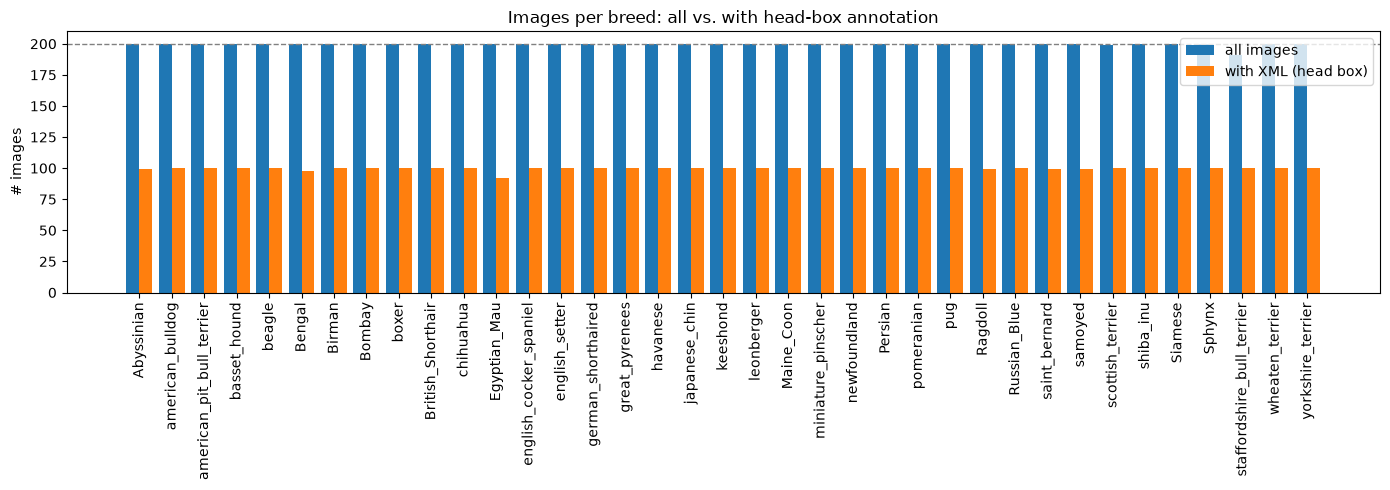

In [34]:
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(counts))
ax.bar(x - 0.2, counts["all_images"], width=0.4, label="all images")
ax.bar(x + 0.2, counts["with_xml"], width=0.4, label="with XML (head box)")
ax.axhline(200, color="gray", ls="--", lw=1)
ax.set_xticks(x)
ax.set_xticklabels(counts.index, rotation=90)
ax.set_ylabel("# images")
ax.set_title("Images per breed: all vs. with head-box annotation")
ax.legend()
plt.tight_layout()
plt.show()

### 💡 4장 인사이트 & 결정사항

**인사이트**
- 전체 이미지 기준으로 CLASS-ID당 191~200장(평균 199.7장)이다. README의 "roughly 200 images for each class"는 **사실이다.**
- XML이 있는 이미지는 CLASS-ID당 **92~100장**이다. 모든 CLASS-ID에서 대략 절반에만 박스가 달려 있다(xml_ratio ≈ 0.5). 공식 trainval 절반에만 박스를 단 결과로 보인다.
- 따라서 박스 기준으로도 **CLASS-ID 간 불균형은 거의 없다** (최소 Egyptian_Mau 92장).
- SPECIES 단위로는 Cat 1,188 : Dog 2,498로 **Dog가 약 2.1배** 많다. SPECIES별 CLASS-ID 수(Cat 12개 vs Dog 25개) 차이 때문이다.

**결정사항**
- CLASS-ID 단위의 리샘플링·가중치는 필요 없다.
- Detection 라벨을 SPECIES(Cat/Dog) 2개로 둘 경우 Cat:Dog = 1:2.1 불균형이 생긴다. Detection 라벨(Cat/Dog)별 AP를 따로 보고한다. 분할은 CLASS-ID 기준 stratified split으로 한다. 각 CLASS-ID는 한 SPECIES에만 속하므로 Cat:Dog 비율도 자동으로 유지된다.

## 5. XML·바운딩 박스 품질 점검

### 5-1. 이미지 메타데이터 수집
XML에 적힌 크기와 비교하기 위해 모든 jpg를 실제로 열어 크기·모드·포맷을 수집한다. `im.load()`로 끝까지 디코딩해 깨진 파일도 함께 걸러낸다. (7장의 이미지 모드·크기 분석에서도 이 결과를 재사용한다.)

In [35]:
def read_meta(path):
    try:
        with Image.open(path) as im:
            fmt, mode, (w, h) = im.format, im.mode, im.size
            im.load()
        return {"image": path.stem, "format": fmt, "mode": mode, "width": w, "height": h, "ok": True, "error": None}
    except Exception as e:
        return {"image": path.stem, "format": None, "mode": None, "width": np.nan, "height": np.nan,
                "ok": False, "error": repr(e)}


meta_df = pd.DataFrame([read_meta(p) for p in tqdm(jpg_paths, desc="reading images")])
meta_df["split"] = meta_df["image"].map(split_of).fillna("unlisted")
meta_df["species"] = np.where(meta_df["image"].str[0].str.isupper(), "cat", "dog")

print("디코딩 실패:", (~meta_df["ok"]).sum(), "장")
display(meta_df.loc[~meta_df["ok"], ["image", "error"]])
print("실제 파일 포맷 분포:", meta_df["format"].value_counts(dropna=False).to_dict())

reading images: 100%|██████████| 7390/7390 [00:09<00:00, 817.99it/s] 

디코딩 실패: 0 장


,image,error


실제 파일 포맷 분포: {'JPEG': 7380, 'GIF': 6, 'PNG': 4}


### 5-2. XML 파싱
XML마다 `<size>`와 `<object>`(name, pose, truncated, occluded, difficult, bndbox)를 읽어 object 1개당 1행인 DataFrame을 만든다.

In [36]:
def to_num(text):
    try:
        return float(text)
    except (TypeError, ValueError):
        return np.nan


rows = []
for path in xml_paths:
    root = ET.parse(path).getroot()
    size = root.find("size")
    objs = root.findall("object")
    for i, obj in enumerate(objs):
        bb = obj.find("bndbox")
        rows.append({
            "image": path.stem,
            "xml_filename": root.findtext("filename"),
            "xml_w": to_num(size.findtext("width")),
            "xml_h": to_num(size.findtext("height")),
            "xml_depth": to_num(size.findtext("depth")),
            "n_objects": len(objs),
            "obj_idx": i,
            "name": obj.findtext("name"),
            "pose": obj.findtext("pose"),
            "truncated": to_num(obj.findtext("truncated")),
            "occluded": to_num(obj.findtext("occluded")),
            "difficult": to_num(obj.findtext("difficult")),
            **{k: to_num(bb.findtext(k)) for k in ["xmin", "ymin", "xmax", "ymax"]},
        })

box_df = pd.DataFrame(rows).merge(meta_df[["image", "width", "height", "mode", "split"]], on="image", how="left")
box_df["species"] = np.where(box_df["image"].str[0].str.isupper(), "cat", "dog")
print(f"XML {len(xml_paths)}개 → object {len(box_df)}개")
box_df.head()

XML 3686개 → object 3687개


,image,xml_filename,xml_w,xml_h,xml_depth,n_objects,obj_idx,name,pose,truncated,...,difficult,xmin,ymin,xmax,ymax,width,height,mode,split,species
0,Abyssinian_1,Abyssinian_1.jpg,600.0,400.0,3.0,1,0,cat,Frontal,0.0,...,0.0,333.0,72.0,425.0,158.0,600,400,RGB,trainval,cat
1,Abyssinian_10,Abyssinian_10.jpg,375.0,500.0,3.0,1,0,cat,Frontal,0.0,...,0.0,72.0,105.0,288.0,291.0,375,500,RGB,trainval,cat
2,Abyssinian_100,Abyssinian_100.jpg,394.0,500.0,3.0,1,0,cat,Frontal,0.0,...,0.0,151.0,71.0,335.0,267.0,394,500,RGB,trainval,cat
3,Abyssinian_101,Abyssinian_101.jpg,450.0,313.0,3.0,1,0,cat,Frontal,0.0,...,0.0,54.0,36.0,319.0,235.0,450,313,RGB,trainval,cat
4,Abyssinian_102,Abyssinian_102.jpg,500.0,465.0,3.0,1,0,cat,Frontal,0.0,...,0.0,23.0,27.0,325.0,320.0,500,465,RGB,trainval,cat


### 5-3. 메타데이터·좌표 유효성 검사
- XML `<filename>`이 실제 파일명과 같은지
- XML `<size>`가 실제 이미지 크기와 같은지 (가로·세로가 뒤바뀐 경우 포함)
- 좌표가 이미지 경계를 벗어나거나 `xmin >= xmax`처럼 뒤집혀 있는지, 결측값이 있는지
- XML `<name>`(cat/dog)이 파일명 대소문자 규칙으로 정한 SPECIES와 같은지

In [37]:
checks = {
    "filename 불일치": box_df["xml_filename"] != box_df["image"] + ".jpg",
    "size 불일치": (box_df["xml_w"] != box_df["width"]) | (box_df["xml_h"] != box_df["height"]),
    "size 가로세로 뒤바뀜": (box_df["xml_w"] == box_df["height"]) & (box_df["xml_h"] == box_df["width"])
                          & (box_df["width"] != box_df["height"]),
    "좌표 결측": box_df[["xmin", "ymin", "xmax", "ymax"]].isna().any(axis=1),
    "xmin >= xmax": box_df["xmin"] >= box_df["xmax"],
    "ymin >= ymax": box_df["ymin"] >= box_df["ymax"],
    "xmin/ymin < 0": (box_df["xmin"] < 0) | (box_df["ymin"] < 0),
    "xmax > width": box_df["xmax"] > box_df["width"],
    "ymax > height": box_df["ymax"] > box_df["height"],
    "name ≠ 파일명 종": box_df["name"] != box_df["species"],
}
check_df = pd.Series({k: int(v.sum()) for k, v in checks.items()}).to_frame("count")
display(check_df)

bad_mask = np.logical_or.reduce(list(checks.values()))
box_df.loc[bad_mask, ["image", "xml_w", "xml_h", "width", "height", "xmin", "ymin", "xmax", "ymax", "name"]]

,count
filename 불일치,0
size 불일치,0
size 가로세로 뒤바뀜,0
좌표 결측,0
xmin >= xmax,0
ymin >= ymax,0
xmin/ymin < 0,0
xmax > width,0
ymax > height,0
name ≠ 파일명 종,0


,image,xml_w,xml_h,width,height,xmin,ymin,xmax,ymax,name


### 5-4. object 개수와 플래그 분포
XML당 object 개수, `pose` / `truncated` / `occluded` / `difficult` 값 분포를 확인한다.

In [38]:
print("XML당 object 개수:", box_df.drop_duplicates("image")["n_objects"].value_counts().to_dict())
display(box_df[box_df["n_objects"] > 1][["image", "obj_idx", "name", "xmin", "ymin", "xmax", "ymax", "width", "height"]])

for col in ["pose", "truncated", "occluded", "difficult"]:
    print(f"{col:10s}:", box_df[col].value_counts(dropna=False).to_dict())

XML당 object 개수: {1: 3685, 2: 1}


,image,obj_idx,name,xmin,ymin,xmax,ymax,width,height
105,Bengal_105,0,cat,49.0,125.0,111.0,168.0,500,466
106,Bengal_105,1,cat,397.0,103.0,451.0,132.0,500,466


pose      : {'Frontal': 3687}
truncated : {0.0: 3687}
occluded  : {0.0: 3687}
difficult : {0.0: 3687}


### 💡 5장 인사이트 & 결정사항

**인사이트**
- 7,390장 모두 디코딩에 성공했다 (깨진 파일 0장).
- 다만 **확장자는 `.jpg`인데 실제 포맷이 GIF(6장)·PNG(4장)인 파일**이 있다.
- XML 3,686개 → object 3,687개. filename·size 불일치, 좌표 결측·뒤집힘·경계 이탈, XML `<name>`과 SPECIES의 불일치가 **모두 0건**이다. 박스 품질은 수치상 매우 깨끗하다.
- XML당 object는 1개가 기본이고, **`Bengal_105` 1장만 object 2개**다 (고양이 두 마리).
- `pose`는 전부 `Frontal`, `truncated`·`occluded`·`difficult`는 전부 0이다. **정보가 없는 필드**다.

**결정사항**
- 이미지는 **PIL로 열어 `.convert("RGB")`로 통일**한다. 확장자가 아니라 실제 내용으로 포맷을 판별해야 하기 때문이다. OpenCV는 버전에 따라 GIF를 못 읽을 수 있다.
- Dataset은 이미지 1장에 **박스 N개**를 반환하는 구조로 만들고, `collate_fn`으로 가변 길이 target을 처리한다.
- `difficult` 플래그는 평가에서 고려하지 않는다 (전부 0).

## 6. 박스 위치 시각적 검증

수치 검사로는 "박스가 실제로 머리를 감싸는지"를 알 수 없으므로, 표본을 눈으로 확인한다.
- CLASS-ID마다 XML이 있는 이미지 1장씩 무작위로 뽑아 37장을 그린다.
- object가 2개인 이미지, `truncated=1`인 이미지 같은 예외 케이스가 있으면 따로 그린다.

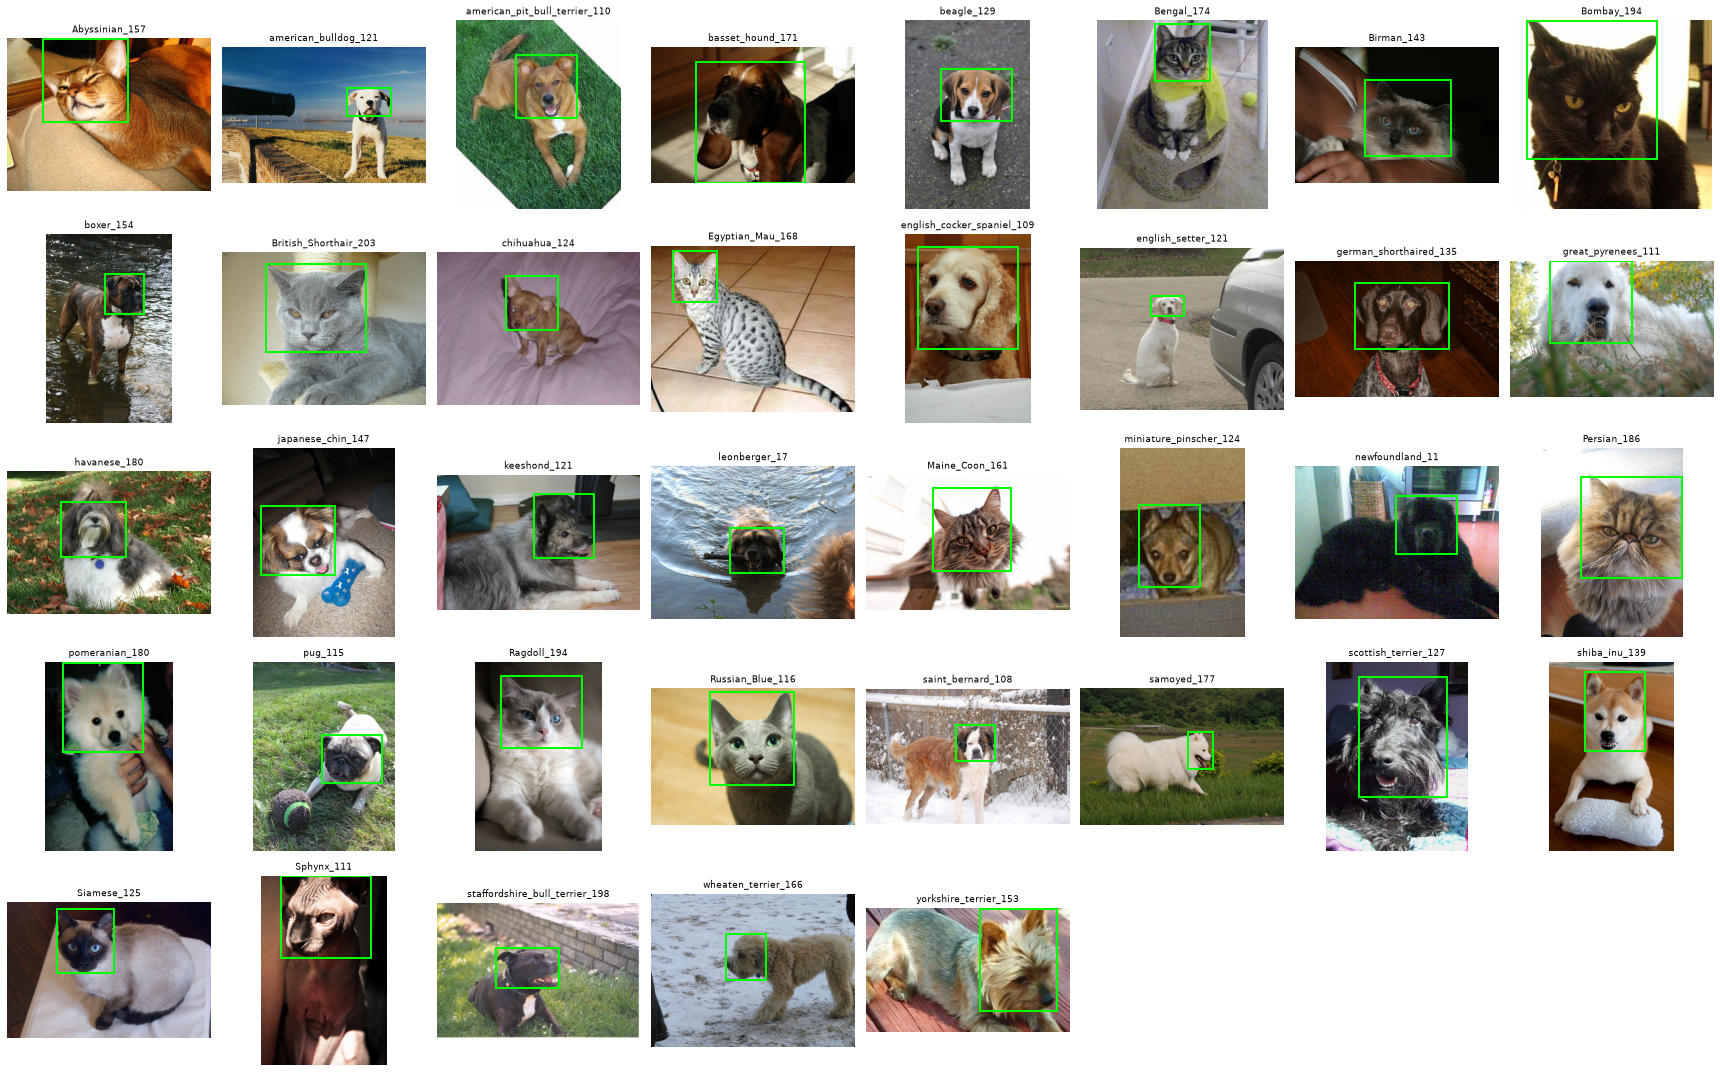

In [39]:
def draw_boxes(ax, name, title=None, color="lime"):
    img = Image.open(IMG_DIR / f"{name}.jpg").convert("RGB")
    ax.imshow(img)
    for _, r in box_df[box_df["image"] == name].iterrows():
        ax.add_patch(patches.Rectangle((r["xmin"], r["ymin"]), r["xmax"] - r["xmin"], r["ymax"] - r["ymin"],
                                       fill=False, edgecolor=color, linewidth=2))
    ax.set_title(title or name, fontsize=9)
    ax.axis("off")


def show_grid(names, ncols=8, titles=None, cell=3.0):
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * cell, nrows * cell), dpi=72)  # 사진 그리드는 노트북 용량을 위해 저해상도
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        if i < len(names):
            draw_boxes(ax, names[i], titles[i] if titles else None)
        else:
            ax.axis("off")
    plt.tight_layout()
    plt.show()


xml_img_df = box_df.drop_duplicates("image").assign(breed=lambda d: d["image"].map(breed_of))
per_class = (xml_img_df.groupby("breed").sample(n=1, random_state=SEED)
             .set_index("breed").reindex(breed_order)["image"].tolist())
show_grid(per_class)

object 2개 이상: 1장, truncated=1: 0장


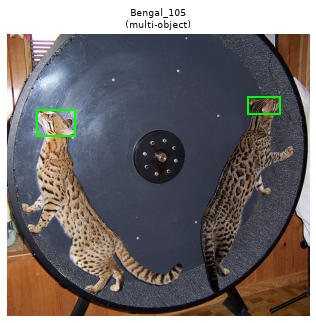

In [40]:
special = box_df[box_df["n_objects"] > 1]["image"].unique().tolist()
truncated = box_df[box_df["truncated"] == 1]["image"].unique().tolist()
sample_trunc = random.Random(SEED).sample(truncated, min(7, len(truncated)))
print(f"object 2개 이상: {len(special)}장, truncated=1: {len(truncated)}장")
names = special + sample_trunc
show_grid(names, ncols=min(4, len(names)),
          titles=[f"{n}\n(multi-object)" for n in special] + [f"{n}\n(truncated)" for n in sample_trunc],
          cell=4.5)

### 💡 6장 인사이트 & 결정사항

**인사이트**
- CLASS-ID 37개에서 1장씩 뽑은 표본 모두에서 박스가 **귀 일부부터 턱까지 머리 전체를 감싸고 있다.** Cat과 Dog 사이에 박스를 그리는 기준 차이도 눈에 띄지 않는다.
- 머리가 화면 대부분을 차지하는 클로즈업부터, 몸 전체가 나오고 머리가 작은 사진까지 **머리 크기가 다양하다.** 이는 8장의 scale 분포로 정량 확인한다.
- `Bengal_105`는 고양이 두 마리의 머리가 **각각 따로** 라벨링되어 있다. 박스가 작아서 탐지가 어려운 사례다.
- `truncated=1`인 사례는 없다.

**결정사항**
- 표본 검사에서 어노테이션 오류가 발견되지 않았으므로 **박스를 수정하거나 제거하지 않고 그대로 쓴다.**

## 7. 이미지 모드·크기 점검

### 7-1. 이미지 모드 분포
RGB가 아닌 이미지(흑백 `L`, 알파 채널 `RGBA`, 팔레트 `P` 등)가 있으면 그대로 텐서로 바꿀 때 채널 수가 달라 에러가 난다. split·SPECIES별로 모드 분포를 확인한다.

In [41]:
display(pd.crosstab(meta_df["split"], meta_df["mode"], margins=True))
display(pd.crosstab(meta_df["species"], meta_df["mode"]))
non_rgb = meta_df[meta_df["mode"] != "RGB"][["image", "mode", "format", "split", "width", "height"]]
non_rgb.assign(has_xml=non_rgb["image"].isin(xml_names))

mode,L,P,RGB,RGBA,All
split,,,,,
test,0,0,3668,1,3669
trainval,0,0,3678,2,3680
unlisted,3,6,32,0,41
All,3,6,7378,3,7390


mode,L,P,RGB,RGBA
species,,,,
cat,1,6,2390,3
dog,2,0,4988,0


,image,mode,format,split,width,height,has_xml
136,Abyssinian_34,P,GIF,unlisted,250,202,False
148,Abyssinian_5,RGBA,PNG,test,200,150,False
1033,Egyptian_Mau_129,L,JPEG,unlisted,299,325,True
1042,Egyptian_Mau_139,P,GIF,unlisted,350,250,False
1043,Egyptian_Mau_14,RGBA,PNG,trainval,582,800,False
1049,Egyptian_Mau_145,P,GIF,unlisted,216,188,False
1070,Egyptian_Mau_167,P,GIF,unlisted,183,275,False
1079,Egyptian_Mau_177,P,GIF,unlisted,246,175,False
1089,Egyptian_Mau_186,RGBA,PNG,trainval,183,275,False
1095,Egyptian_Mau_191,P,GIF,unlisted,300,214,False


### 7-1-1. `.convert("RGB")` 전후 비교
RGB가 아닌 12장을 `.convert("RGB")` 전후로 나란히 그려, 변환할 때 정보가 손실되거나 색이 왜곡되지 않는지 확인한다.
- **원본 배열 그대로**: PIL이 들고 있는 원본 배열을 그대로 그린 것이다. `L`은 회색조 1채널, `P`는 색이 아니라 **팔레트 인덱스**(0~255 정수), `RGBA`는 알파 채널을 포함한 4채널이다.
- **convert("RGB")**: 모델에 실제로 들어가는 3채널 이미지다.
- **변환 검증**: `L`은 변환 후 R=G=B인지(R−G 차이 맵), `RGBA`는 버려지는 알파 채널에 투명 영역이 있었는지(알파 맵), `P`는 GIF 투명색 지정(`transparency`)이 있었는지(투명 마스크)를 확인한다.

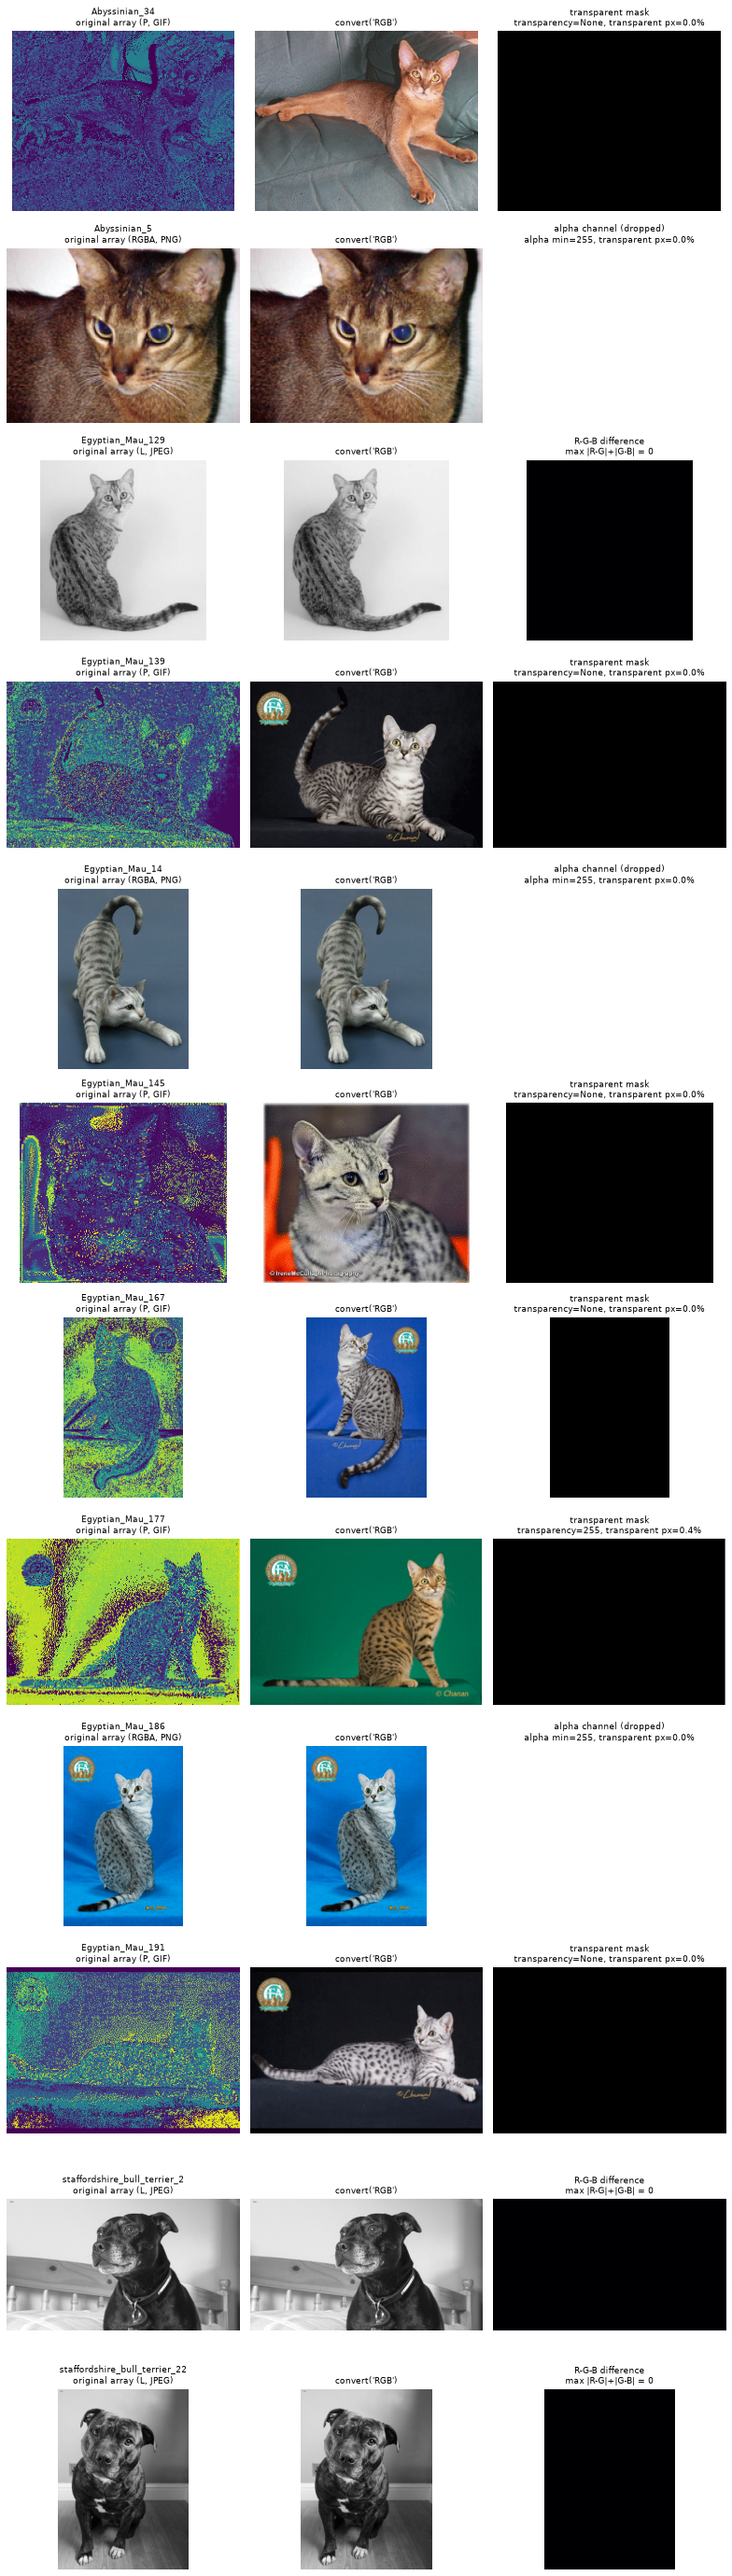

,image,mode,format,split,has_xml,array_before,array_after,check
0,Abyssinian_34,P,GIF,unlisted,False,"(202, 250)","(202, 250, 3)","transparency=None, transparent px=0.0%"
1,Abyssinian_5,RGBA,PNG,test,False,"(150, 200, 4)","(150, 200, 3)","alpha min=255, transparent px=0.0%"
2,Egyptian_Mau_129,L,JPEG,unlisted,True,"(325, 299)","(325, 299, 3)",max |R-G|+|G-B| = 0
3,Egyptian_Mau_139,P,GIF,unlisted,False,"(250, 350)","(250, 350, 3)","transparency=None, transparent px=0.0%"
4,Egyptian_Mau_14,RGBA,PNG,trainval,False,"(800, 582, 4)","(800, 582, 3)","alpha min=255, transparent px=0.0%"
5,Egyptian_Mau_145,P,GIF,unlisted,False,"(188, 216)","(188, 216, 3)","transparency=None, transparent px=0.0%"
6,Egyptian_Mau_167,P,GIF,unlisted,False,"(275, 183)","(275, 183, 3)","transparency=None, transparent px=0.0%"
7,Egyptian_Mau_177,P,GIF,unlisted,False,"(175, 246)","(175, 246, 3)","transparency=255, transparent px=0.4%"
8,Egyptian_Mau_186,RGBA,PNG,trainval,False,"(275, 183, 4)","(275, 183, 3)","alpha min=255, transparent px=0.0%"
9,Egyptian_Mau_191,P,GIF,unlisted,False,"(214, 300)","(214, 300, 3)","transparency=None, transparent px=0.0%"


In [42]:
def checkerboard(h, w, size=16):
    """투명 영역을 드러내기 위한 체커보드 배경."""
    yy, xx = np.mgrid[0:h, 0:w]
    board = ((yy // size + xx // size) % 2).astype(np.float32)
    return np.stack([0.75 + 0.2 * board] * 3, axis=-1)


conv_rows = []
non_rgb_names = non_rgb["image"].tolist()
fig, axes = plt.subplots(len(non_rgb_names), 3, figsize=(11, 3.2 * len(non_rgb_names)), dpi=72)
for row, name in enumerate(non_rgb_names):
    with Image.open(IMG_DIR / f"{name}.jpg") as im:
        im.load()
        fmt, orig = im.format, im.copy()  # copy()는 format 정보를 잃으므로 미리 저장
    rgb = orig.convert("RGB")
    arr_o, arr_r = np.asarray(orig), np.asarray(rgb).astype(np.int16)
    ax_o, ax_r, ax_c = axes[row]

    # (1) 원본 배열 그대로
    if orig.mode == "L":
        ax_o.imshow(arr_o, cmap="gray", vmin=0, vmax=255)
    elif orig.mode == "P":
        ax_o.imshow(arr_o, cmap="viridis", vmin=0, vmax=255)  # 인덱스 값을 그대로 색으로 표시
    else:  # RGBA: 체커보드 위에 알파 합성
        a = arr_o[..., 3:4] / 255.0
        ax_o.imshow(arr_o[..., :3] / 255.0 * a + checkerboard(*arr_o.shape[:2]) * (1 - a))

    # (2) convert("RGB") 결과
    ax_r.imshow(rgb)

    # (3) 변환 검증
    note = ""
    if orig.mode == "L":
        diff = np.abs(arr_r[..., 0] - arr_r[..., 1]) + np.abs(arr_r[..., 1] - arr_r[..., 2])
        ax_c.imshow(diff, cmap="magma", vmin=0, vmax=max(1, diff.max()))
        note = f"max |R-G|+|G-B| = {diff.max()}"
        check_title = "R-G-B difference"
    elif orig.mode == "RGBA":
        alpha = arr_o[..., 3]
        ax_c.imshow(alpha, cmap="gray", vmin=0, vmax=255)
        note = f"alpha min={alpha.min()}, transparent px={(alpha < 255).mean():.1%}"
        check_title = "alpha channel (dropped)"
    else:  # P
        t = orig.info.get("transparency")
        mask = (arr_o == t) if isinstance(t, int) else np.zeros(arr_o.shape, bool)
        ax_c.imshow(mask, cmap="gray", vmin=0, vmax=1)
        note = f"transparency={t}, transparent px={mask.mean():.1%}"
        check_title = "transparent mask"

    for ax, title in [(ax_o, f"{name}\noriginal array ({orig.mode}, {fmt})"),
                      (ax_r, f"convert('RGB')"),
                      (ax_c, f"{check_title}\n{note}")]:
        ax.set_title(title, fontsize=9)
        ax.axis("off")

    conv_rows.append({
        "image": name, "mode": orig.mode, "format": fmt, "split": split_of.get(name, "unlisted"),
        "has_xml": name in xml_names, "array_before": arr_o.shape, "array_after": arr_r.shape, "check": note,
    })
plt.tight_layout()
plt.show()

pd.DataFrame(conv_rows)

**7-1-1 확인 결과**
- **L (3장)**: 변환 후 R=G=B다 (차이 0). 회색조 값을 3채널에 복제할 뿐이라 **정보 손실이 없다.** 학습 데이터에 들어오는 `Egyptian_Mau_129`도 여기에 해당한다.
- **P (6장, 모두 GIF)**: 원본 배열은 색이 아니라 **팔레트 인덱스**라서 그대로 그리면 노이즈처럼 보인다. 변환하면 팔레트가 적용되어 정상 색으로 복원된다.
  - `np.asarray()`로 바로 텐서를 만들면 이 인덱스가 픽셀값으로 들어가서 **에러 없이 잘못된 입력**이 된다. 가장 위험한 경우다.
  - `Egyptian_Mau_177`만 투명색이 지정되어 있지만, 투명 픽셀은 0.4%에 불과하다.
- **RGBA (3장, 모두 PNG)**: 알파 최솟값이 255로 **투명 픽셀이 없다.** 알파 채널을 버려도 잃는 것이 없다.
  - `Abyssinian_5`는 공식 `test.txt`에 있다. 정성 평가용 추론에서도 변환이 필요하다.
- 변환 전 배열 shape는 `(H, W)` 또는 `(H, W, 4)`로 제각각이고, 변환 후에는 모두 `(H, W, 3)`이 된다. 배치로 쌓으려면 채널 수가 같아야 하므로 **`.convert("RGB")`는 필수**이고, 이 데이터에서는 변환으로 생기는 부작용도 없다.

### 7-2. 이미지 크기·종횡비 분포
SSD는 고정 크기(예: 300×300) 입력을 쓰므로, 원본 크기·종횡비가 얼마나 다양한지 보고 리사이즈 정책을 정한다.

In [43]:
meta_df["aspect"] = meta_df["width"] / meta_df["height"]
meta_df["short_side"] = meta_df[["width", "height"]].min(axis=1)

display(meta_df[["width", "height", "aspect", "short_side"]].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2))
display(meta_df.groupby("split")[["width", "height", "aspect"]].median().round(2))
display(meta_df.groupby("species")[["width", "height", "aspect"]].median().round(2))

orient = pd.cut(meta_df["aspect"], [0, 0.95, 1.05, np.inf], labels=["portrait", "square", "landscape"])
print("방향 분포:", orient.value_counts().to_dict())
print("짧은 변 < 300px:", (meta_df["short_side"] < 300).sum(), "장")

,width,height,aspect,short_side
count,7390.00,7390.00,7390.00,7390.00
mean,436.75,390.91,1.17,349.21
std,115.88,109.59,0.33,83.81
min,114.00,103.00,0.42,103.00
1%,200.00,196.00,0.64,183.00
5%,281.00,225.00,0.67,225.00
50%,500.00,375.00,1.33,335.00
95%,500.00,500.00,1.51,456.00
99%,600.00,550.99,1.72,500.00
max,3264.00,2606.00,2.56,2448.00


,width,height,aspect
split,,,
test,500.0,375.0,1.33
trainval,500.0,375.0,1.33
unlisted,300.0,284.0,1.32


,width,height,aspect
species,,,
cat,500.0,375.0,1.33
dog,500.0,375.0,1.33


방향 분포: {'landscape': 4804, 'portrait': 2275, 'square': 311}
짧은 변 < 300px: 1070 장


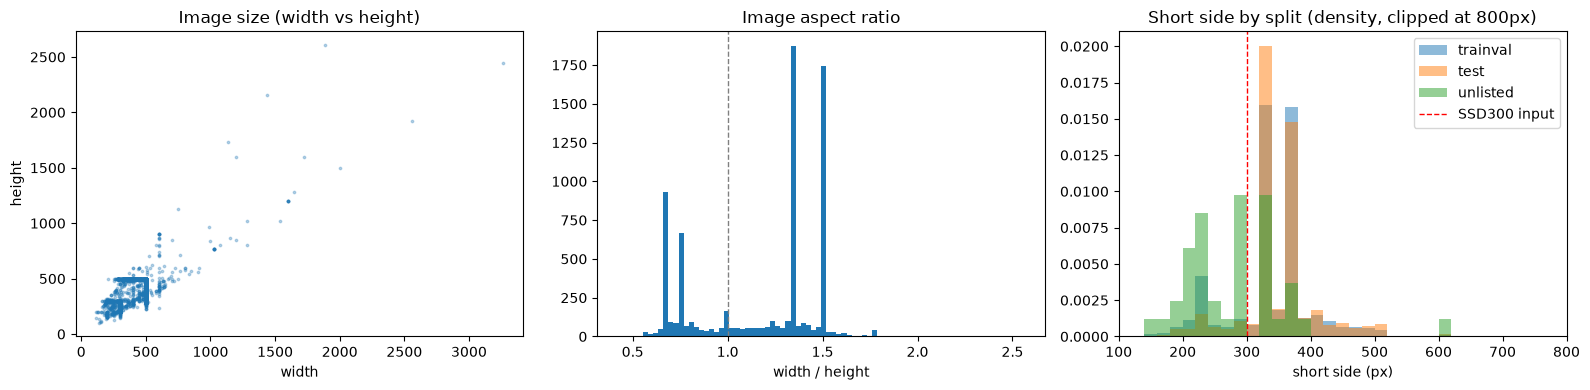

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(meta_df["width"], meta_df["height"], s=3, alpha=0.3)
axes[0].set(xlabel="width", ylabel="height", title="Image size (width vs height)")
axes[1].hist(meta_df["aspect"], bins=80)
axes[1].axvline(1, color="gray", ls="--", lw=1)
axes[1].set(xlabel="width / height", title="Image aspect ratio")
for sp in ["trainval", "test", "unlisted"]:
    axes[2].hist(meta_df.loc[meta_df["split"] == sp, "short_side"], bins=np.arange(100, 820, 20),
                 alpha=0.5, label=sp, density=True)
axes[2].axvline(300, color="red", ls="--", lw=1, label="SSD300 input")
axes[2].set(xlabel="short side (px)", title="Short side by split (density, clipped at 800px)", xlim=(100, 800))
axes[2].legend()
plt.tight_layout()
plt.show()

### 💡 7장 인사이트 & 결정사항

**인사이트**
- RGB가 아닌 이미지는 총 12장이다: L 3장, P 6장, RGBA 3장. P 6장은 모두 실제 GIF이고, RGBA 3장은 실제 PNG다.
- 대부분 목록 외 이미지라 Detection 데이터에 들어오는 것은 **`Egyptian_Mau_129`(흑백 L) 1장뿐**이다. RGBA 2장(`Egyptian_Mau_14`, `Egyptian_Mau_186`)은 trainval에 있지만 XML이 없어 어차피 제외된다.
- 크기 중앙값은 **500×375**이다. 종횡비는 연속적으로 퍼져 있지 않고 **4:3(1.33)·3:2(1.5) 가로와 그 세로판(0.75·0.67)에 뾰족하게 몰려 있다** (카메라 기본 비율). 가로 4,804장, 세로 2,275장, 정사각 311장이다.
- 대부분 짧은 변 183~500px(1~99%) 범위에 있다. 최대 3264×2606 같은 큰 이상치가 소수 있다.
- 짧은 변이 300px보다 작은 이미지가 1,070장(14%)이라, SSD300 입력으로 쓰면 일부는 **업샘플링**된다.
- split·SPECIES별 크기 분포는 사실상 같다 (중앙값 모두 500×375). 크기에 따른 split 편향은 없다.

**결정사항**
- 로딩 시 `.convert("RGB")`를 필수로 적용한다 (5장 결정과 동일).
- 입력은 SSD 표준대로 **종횡비를 무시하고 300×300으로 바로 리사이즈**한다. 대부분 4:3 가로 이미지라 세로로 늘어나는 왜곡이 생기는데, 이 영향은 8장의 리사이즈 후 박스 종횡비로 확인한다.
- 업샘플링되는 저해상도 이미지가 일부 있지만 제외하지 않는다.

## 8. 바운딩 박스 통계 분석

SSD의 default box(anchor)는 "이미지 대비 크기(scale)"와 "종횡비(aspect ratio)"로 정의된다. 실제 머리 박스가 어떤 scale·종횡비·위치에 분포하는지 보고 anchor 설정의 근거로 삼는다.
- `scale = sqrt(박스 면적 / 이미지 면적)` : SSD 논문의 s_k와 같은 정의
- SSD는 입력을 정사각형으로 리사이즈하므로, 종횡비는 **리사이즈 후 기준**인 `(box_w / W) / (box_h / H)`로도 함께 계산한다.
- 비교 기준선은 torchvision `ssd300_vgg16`의 기본 설정(scales 0.07~1.05, aspect ratios 1, 2, 3, 1/2, 1/3)이다.

In [45]:
b = box_df
b["box_w"] = b["xmax"] - b["xmin"]
b["box_h"] = b["ymax"] - b["ymin"]
b["rel_w"] = b["box_w"] / b["width"]
b["rel_h"] = b["box_h"] / b["height"]
b["rel_area"] = b["rel_w"] * b["rel_h"]
b["scale"] = np.sqrt(b["rel_area"])
b["aspect_raw"] = b["box_w"] / b["box_h"]
b["aspect_resized"] = b["rel_w"] / b["rel_h"]
b["cx"] = (b["xmin"] + b["xmax"]) / 2 / b["width"]
b["cy"] = (b["ymin"] + b["ymax"]) / 2 / b["height"]

stat_cols = ["rel_w", "rel_h", "rel_area", "scale", "aspect_raw", "aspect_resized", "cx", "cy"]
display(b[stat_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(3))
display(b.groupby("species")[["scale", "aspect_raw", "aspect_resized"]].median().round(3))

,rel_w,rel_h,rel_area,scale,aspect_raw,aspect_resized,cx,cy
count,3687.000,3687.000,3687.000,3687.000,3687.000,3687.000,3687.000,3687.000
mean,0.412,0.447,0.206,0.422,1.036,0.966,0.498,0.368
std,0.187,0.183,0.158,0.166,0.209,0.376,0.121,0.106
min,0.054,0.062,0.004,0.061,0.464,0.361,0.121,0.098
1%,0.120,0.146,0.020,0.143,0.619,0.448,0.203,0.161
5%,0.164,0.200,0.038,0.195,0.731,0.545,0.291,0.205
25%,0.270,0.302,0.086,0.294,0.900,0.687,0.430,0.291
50%,0.380,0.419,0.159,0.398,1.008,0.846,0.499,0.361
75%,0.522,0.564,0.288,0.536,1.157,1.182,0.568,0.439
95%,0.774,0.793,0.529,0.727,1.405,1.722,0.705,0.548


,scale,aspect_raw,aspect_resized
species,,,
cat,0.388,0.977,0.796
dog,0.405,1.042,0.867


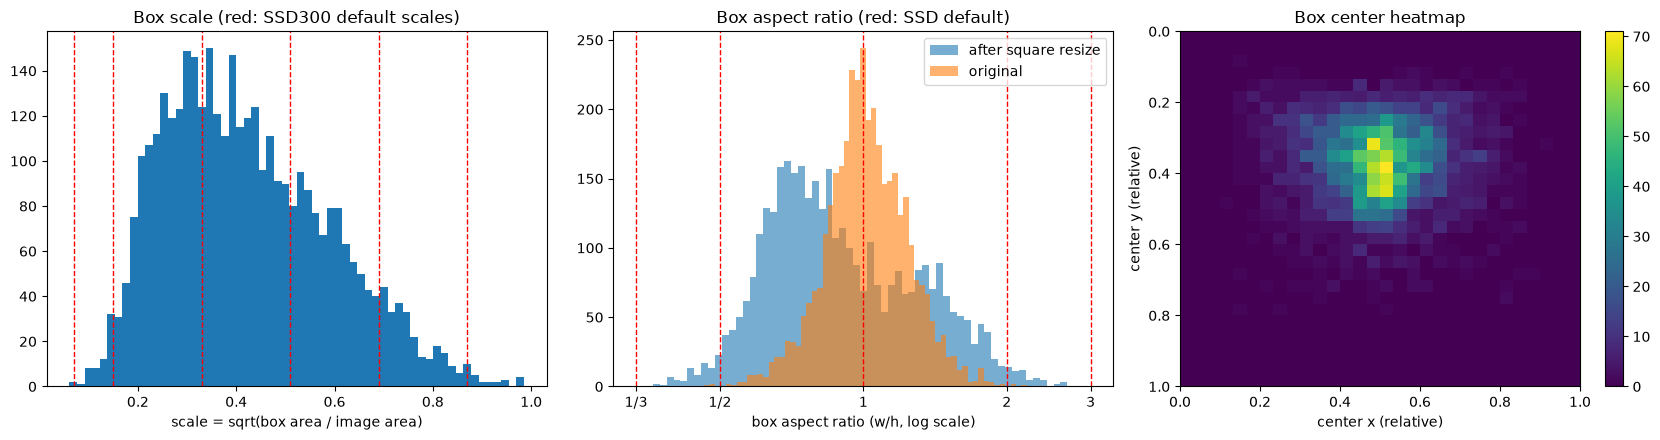

In [46]:
SSD_SCALES = [0.07, 0.15, 0.33, 0.51, 0.69, 0.87]
SSD_ASPECTS = [1/3, 1/2, 1, 2, 3]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(b["scale"], bins=60)
for s in SSD_SCALES:
    axes[0].axvline(s, color="red", ls="--", lw=1)
axes[0].set(xlabel="scale = sqrt(box area / image area)", title="Box scale (red: SSD300 default scales)")

axes[1].hist(np.log2(b["aspect_resized"]), bins=60, alpha=0.6, label="after square resize")
axes[1].hist(np.log2(b["aspect_raw"]), bins=60, alpha=0.6, label="original")
for a in SSD_ASPECTS:
    axes[1].axvline(np.log2(a), color="red", ls="--", lw=1)
axes[1].set_xticks(np.log2(SSD_ASPECTS))
axes[1].set_xticklabels(["1/3", "1/2", "1", "2", "3"])
axes[1].set(xlabel="box aspect ratio (w/h, log scale)", title="Box aspect ratio (red: SSD default)")
axes[1].legend()

h = axes[2].hist2d(b["cx"], b["cy"], bins=30, range=[[0, 1], [0, 1]], cmap="viridis")
axes[2].invert_yaxis()
axes[2].set(xlabel="center x (relative)", ylabel="center y (relative)", title="Box center heatmap")
fig.colorbar(h[3], ax=axes[2])
plt.tight_layout()
plt.show()

### 8-1. 극단값 박스 확인
scale·종횡비가 가장 작거나 큰 박스를 직접 그려, 이상치인지 실제로 그런 이미지인지 확인한다.

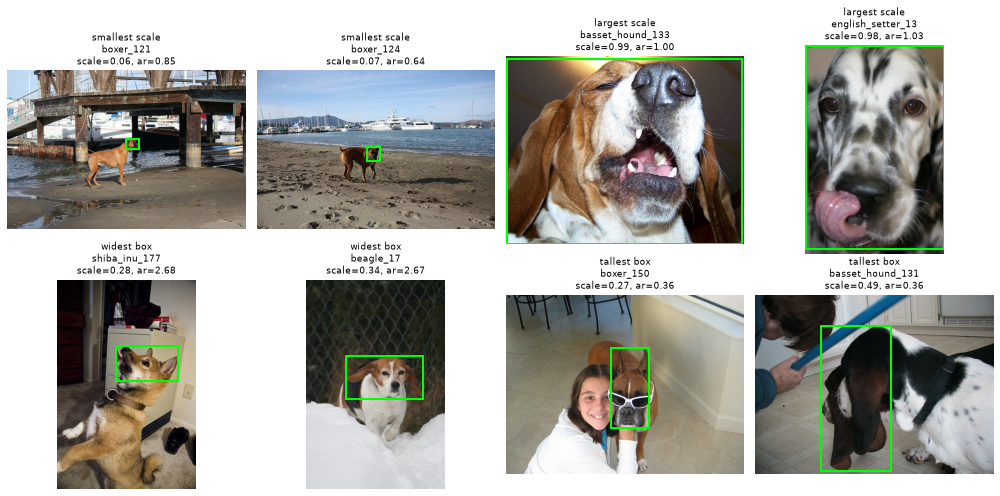

In [47]:
extremes = {
    "smallest scale": b.nsmallest(2, "scale"),
    "largest scale": b.nlargest(2, "scale"),
    "widest box": b.nlargest(2, "aspect_resized"),
    "tallest box": b.nsmallest(2, "aspect_resized"),
}
names, titles = [], []
for label, df in extremes.items():
    for _, r in df.iterrows():
        names.append(r["image"])
        titles.append(f"{label}\n{r['image']}\nscale={r['scale']:.2f}, ar={r['aspect_resized']:.2f}")
show_grid(names, ncols=4, titles=titles, cell=3.5)

### 💡 8장 인사이트 & 결정사항

**인사이트**
- **Scale:** 중앙값 0.40이고, 대부분 0.14~0.84(1~99%) 범위에 있다.
  - scale < 0.1인 아주 작은 머리는 7개(0.2%)뿐이다. torchvision SSD300의 가장 작은 default scale(0.07)이 담당하는 구간에는 박스가 거의 없다.
  - 300×300 입력 기준으로 박스 짧은 변은 1% 지점이 약 35px, 중앙값이 약 100px다. SSD가 다루기 어려운 초소형 객체 문제는 크지 않다.
- **종횡비:**
  - 원본 기준으로는 중앙값 1.01로 거의 정사각형이다 (머리는 대체로 정사각형).
  - 300×300으로 리사이즈하면 4:3 가로 이미지가 많아서 **중앙값이 0.85로 세로로 길어지고, 분포 폭도 넓어진다** (0.45~2.09, 1~99%).
  - 그래도 **96%가 [1/2, 2] 안에 있고, 1/3 미만이나 3 초과는 0개**다.
- **위치:** 중심이 가로 0.5, 세로 **0.36 부근(화면 위쪽 중앙)**에 몰려 있다. 사진 구도 편향(동물 머리를 화면 위 중앙에 두고 찍음)으로 보인다.
- 극단값 박스(작은 머리, 머리가 화면 전체인 클로즈업, 사람과 함께 찍혀 세로로 긴 머리)도 모두 실제로 그런 이미지이고 라벨 오류가 아니다.

**결정사항**
- **Anchor 종횡비는 {1, 2, 1/2}면 충분하다.** 기본 설정의 3, 1/3은 해당하는 박스가 없으니, 이를 뺀 설정을 기본 설정과 비교하는 실험 후보로 둔다.
- Anchor scale은 torchvision 기본값(0.07~1.05)이 실제 분포(0.14~0.84)를 충분히 덮으므로 **기본값을 유지**한다.
- 박스 위치가 화면 위 중앙에 몰려 있으므로, 위치 다양성을 늘리려고 **랜덤 크롭·확대 증강을 쓴다** (9장).

## 9. 데이터 증강 미리보기

Detection에서는 이미지를 변형하면 **박스 좌표도 똑같이 변환**해야 한다. torchvision `transforms.v2`는 `tv_tensors.BoundingBoxes`를 함께 넘기면 박스를 자동으로 변환해 주므로 이를 사용한다.
- 좌우 반전 / 미세 회전(10°) / 얼굴을 반드시 포함하는 랜덤 크롭·확대 / 밝기·대비 조절 / 가우시안 노이즈
- SPECIES(Cat/Dog)와 박스 크기가 다른 대표 이미지 3장에 각각 적용하고, 변환된 박스를 겹쳐 그려 확인한다.

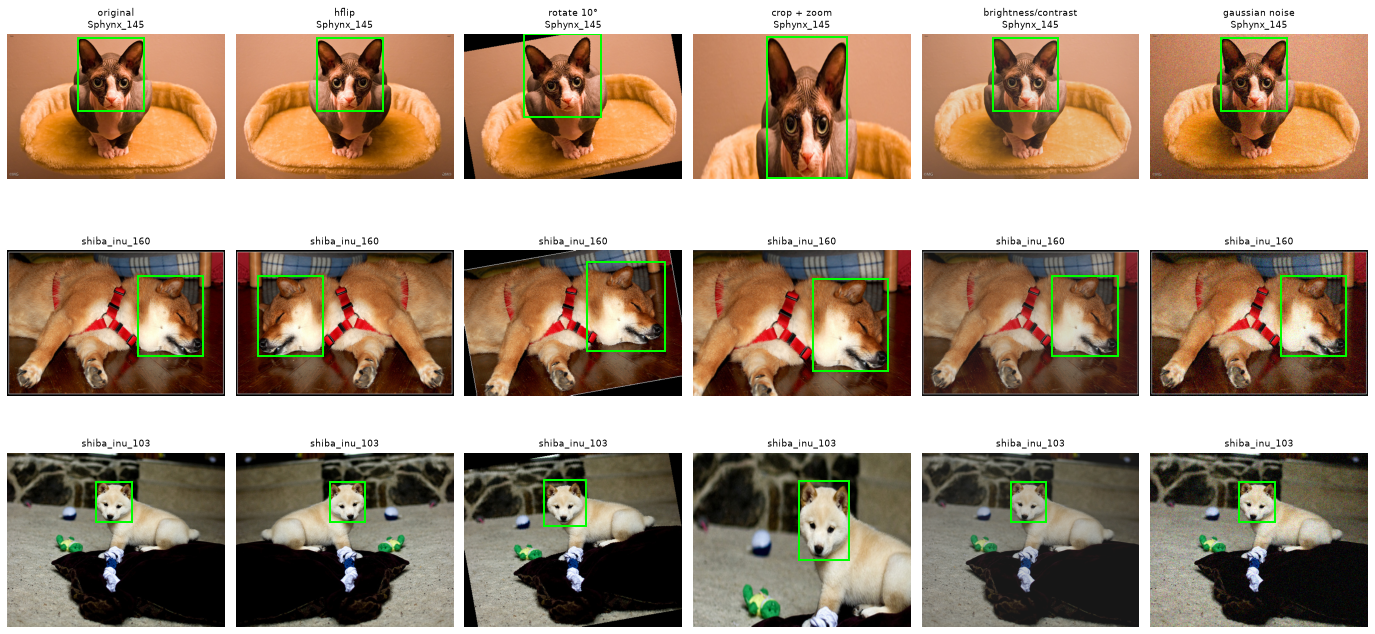

In [48]:
import torch
from torchvision import tv_tensors
from torchvision.transforms import v2
from torchvision.transforms.v2 import functional as TF

torch.manual_seed(SEED)


def load_sample(name):
    img = Image.open(IMG_DIR / f"{name}.jpg").convert("RGB")
    boxes = box_df.loc[box_df["image"] == name, ["xmin", "ymin", "xmax", "ymax"]].to_numpy(dtype=np.float32)
    return (tv_tensors.Image(TF.pil_to_tensor(img)),
            tv_tensors.BoundingBoxes(torch.tensor(boxes), format="XYXY", canvas_size=(img.height, img.width)))


class RandomCropContainingBoxes(torch.nn.Module):
    """모든 박스를 포함하는 영역을 무작위로 잘라낸 뒤 원래 크기로 확대한다 (얼굴이 잘려 나가지 않는 크롭)."""

    def __init__(self, min_ratio=0.5):
        super().__init__()
        self.min_ratio = min_ratio

    def forward(self, img, boxes):
        H, W = img.shape[-2:]
        x0, y0 = boxes[:, 0].min().item(), boxes[:, 1].min().item()
        x1, y1 = boxes[:, 2].max().item(), boxes[:, 3].max().item()
        cw = random.uniform(max(x1 - x0, self.min_ratio * W), W)
        ch = random.uniform(max(y1 - y0, self.min_ratio * H), H)
        left = random.uniform(max(0, x1 - cw), min(x0, W - cw))
        top = random.uniform(max(0, y1 - ch), min(y0, H - ch))
        top, left, ch, cw = int(top), int(left), int(np.ceil(ch)), int(np.ceil(cw))
        img, boxes = TF.crop(img, top, left, ch, cw), TF.crop(boxes, top, left, ch, cw)
        return TF.resize(img, [H, W], antialias=True), TF.resize(boxes, [H, W])


AUGS = {
    "original": None,
    "hflip": v2.RandomHorizontalFlip(p=1.0),
    "rotate 10°": v2.Compose([v2.RandomRotation(degrees=(10, 10)), v2.ClampBoundingBoxes()]),
    "crop + zoom": RandomCropContainingBoxes(min_ratio=0.5),
    "brightness/contrast": v2.ColorJitter(brightness=0.4, contrast=0.4),
    "gaussian noise": v2.Compose([v2.ToDtype(torch.float32, scale=True), v2.GaussianNoise(sigma=0.08)]),
}

def pick_by_scale(species, q):
    df = b[(b["species"] == species) & (b["n_objects"] == 1)]
    return df.iloc[(df["scale"] - df["scale"].quantile(q)).abs().argsort().iloc[0]]["image"]

aug_samples = [pick_by_scale("cat", 0.5), pick_by_scale("dog", 0.5), pick_by_scale("dog", 0.05)]

fig, axes = plt.subplots(len(aug_samples), len(AUGS), figsize=(3.2 * len(AUGS), 3.2 * len(aug_samples)), dpi=72)
for row, name in enumerate(aug_samples):
    img, boxes = load_sample(name)
    for col, (aug_name, aug) in enumerate(AUGS.items()):
        out_img, out_boxes = (img, boxes) if aug is None else aug(img, boxes)
        if out_img.is_floating_point():
            out_img = out_img.clamp(0, 1)
        else:
            out_img = out_img.float() / 255
        ax = axes[row, col]
        ax.imshow(out_img.permute(1, 2, 0).numpy())
        for x0, y0, x1, y1 in out_boxes.tolist():
            ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="lime", linewidth=2))
        ax.set_title(f"{aug_name}\n{name}" if row == 0 else name, fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

### 9-1. 회전 시 박스 팽창 정도
축에 평행한 박스(axis-aligned box)를 θ만큼 회전하면, 회전된 박스를 감싸는 새 박스는 원래보다 커진다 (`w' = w·|cosθ| + h·|sinθ|`). 실제 머리 박스들에 대해 각도별 면적 증가율을 계산해 회전 각도 상한을 정한다.

In [49]:
def rotated_area_ratio(w, h, deg):
    t = np.deg2rad(deg)
    w2 = w * abs(np.cos(t)) + h * abs(np.sin(t))
    h2 = w * abs(np.sin(t)) + h * abs(np.cos(t))
    return (w2 * h2) / (w * h)

rot_table = pd.DataFrame({
    f"{d}°": rotated_area_ratio(b["box_w"], b["box_h"], d).describe(percentiles=[0.5, 0.95])[["mean", "50%", "95%", "max"]]
    for d in [3, 5, 10, 15]
}).round(3)
rot_table

,3°,5°,10°,15°
mean,1.107,1.177,1.349,1.510
50%,1.105,1.175,1.345,1.504
95%,1.113,1.188,1.370,1.541
max,1.139,1.231,1.454,1.664


### 💡 9장 인사이트 & 결정사항

**인사이트**
- `transforms.v2` + `BoundingBoxes`를 쓰면 반전·회전·크롭·리사이즈에 맞춰 **박스도 함께 정확히 변환된다.** 그려 보면 모든 증강에서 박스가 머리를 따라간다.
- **좌우 반전:** 머리는 좌우 대칭에 가까워서 라벨 의미를 해치지 않는다.
- **회전:** 축에 평행한 박스(axis-aligned box)를 회전하면 박스를 감싸는 새 박스가 커진다. 10°에서 면적이 평균 **+35%**, 5°에서 +18%, 3°에서 +11% 커진다. 10° 회전은 머리 바깥의 배경까지 정답 박스에 넣게 되어 **라벨이 느슨해진다.** 그림에서도 회전 후 박스가 원래보다 헐렁하다.
- **얼굴 포함 크롭+확대:** 머리가 잘리지 않는 상태에서 머리 크기·위치를 바꿔준다. 8장의 "작은 머리 vs 클로즈업", "위쪽 중앙 편향" 문제를 직접 완화한다.
- **밝기·대비, 노이즈:** 박스에 영향이 없다. sigma=0.08 노이즈는 눈에 띌 정도라서 너무 강할 수 있다.

**결정사항**
- 학습용 증강:
  - 좌우 반전 (p=0.5)
  - 얼굴 포함 랜덤 크롭+확대 (min_ratio=0.5)
  - 밝기·대비 조절 (±0.3 정도)
- **회전은 ±5° 이내로 제한하거나 쓰지 않는다.** 먼저 회전 없이 기준 성능을 만들고, 필요하면 ±5°를 추가하는 실험을 한다.
- 노이즈는 약하게(sigma ≤ 0.03) 두거나 확률적으로만 적용한다.
- val/test에는 증강 없이 리사이즈와 정규화만 적용한다.

## 10. EDA 결론 정리

| 구분 | 발견 | 결정 |
|---|---|---|
| **평가 데이터** | 공식 `test.txt` 3,669장에 박스 정답이 **0개** | trainval.txt 안에서 XML이 있는 데이터를 **train/val/test = 70/15/15로 재분할** (CLASS-ID 기준 stratified split, 시드 고정). 공식 test는 정성 평가(예측 시각화)에만 사용 |
| **학습 데이터 범위** | trainval.txt 중 XML 보유 3,671장, 목록 외 XML 15개 중 13개는 trainval 복사본 | trainval XML 3,671장 + 복사본이 아닌 2장 = **3,673장** 사용, 복사본 13개 제외 |
| **누수** | 해시 중복 29그룹은 모두 "공식 이미지 + 목록 외 복사본" | 이미지 목록을 split 파일 기준으로 만들고 복사본을 제외하면 누수 없음 |
| **라벨** | 대소문자 규칙·ID 대응 모두 정확, 박스 좌표 오류 0건, 표본 육안 검사 이상 없음 | 라벨·박스 그대로 사용 |
| **클래스 분포** | CLASS-ID당 박스 92~100장으로 균형, SPECIES는 Cat:Dog = 1:2.1 | 리샘플링 없음. Detection 라벨(Cat/Dog)별 AP는 별도로 결과 보고 |
| **다중 객체** | `Bengal_105` 1장만 박스 2개 | Dataset은 박스 N개 반환, `collate_fn`으로 처리 |
| **이미지 로딩** | `.jpg`이지만 실제로 GIF/PNG인 파일, L/P/RGBA 모드 존재 | **PIL + `.convert("RGB")`** 필수 |
| **입력 크기** | 중앙값 500×375, 종횡비는 4:3·3:2(가로/세로)에 집중, 짧은 변 300px 미만 14% | 종횡비를 무시하고 **300×300**으로 리사이즈 |
| **Anchor** | scale 0.14~0.84, 리사이즈 후 종횡비 96%가 [1/2, 2], 1/3·3 해당 없음 | scale은 기본값 유지. 종횡비 {1, 2, 1/2} 축소 설정을 비교 실험 후보로 |
| **증강** | 10° 회전 시 박스 면적 +35%로 라벨이 느슨해짐, 박스가 위쪽 중앙에 편향 | 좌우 반전 + 얼굴 포함 크롭·확대 + 밝기·대비. 회전은 적용하지 않는다. |
| **평가 지표** | Detection 과제 | IoU 기반 **mAP@0.5**와 **mAP@[0.5:0.95]**, Detection 라벨(Cat/Dog)별 AP, 평균 IoU |

**다음 단계**: 위 결정에 따라 3,673장의 어노테이션 테이블과 CLASS-ID 기준 stratified 분할 파일을 만들고, 이를 공통으로 쓰는 Dataset을 구현한 뒤 SSD300 baseline을 학습한다.